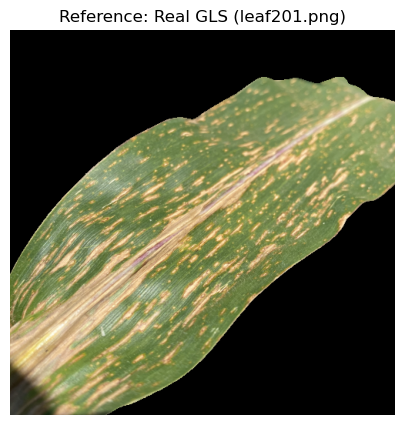

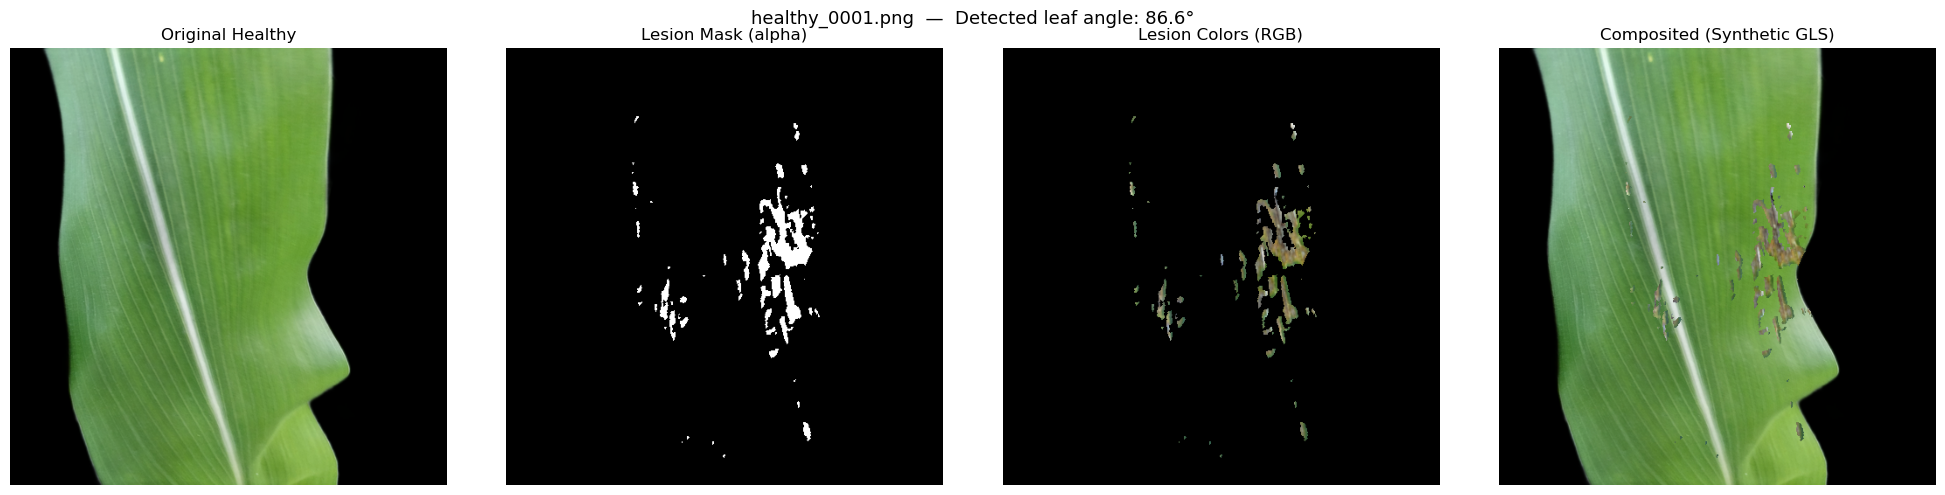

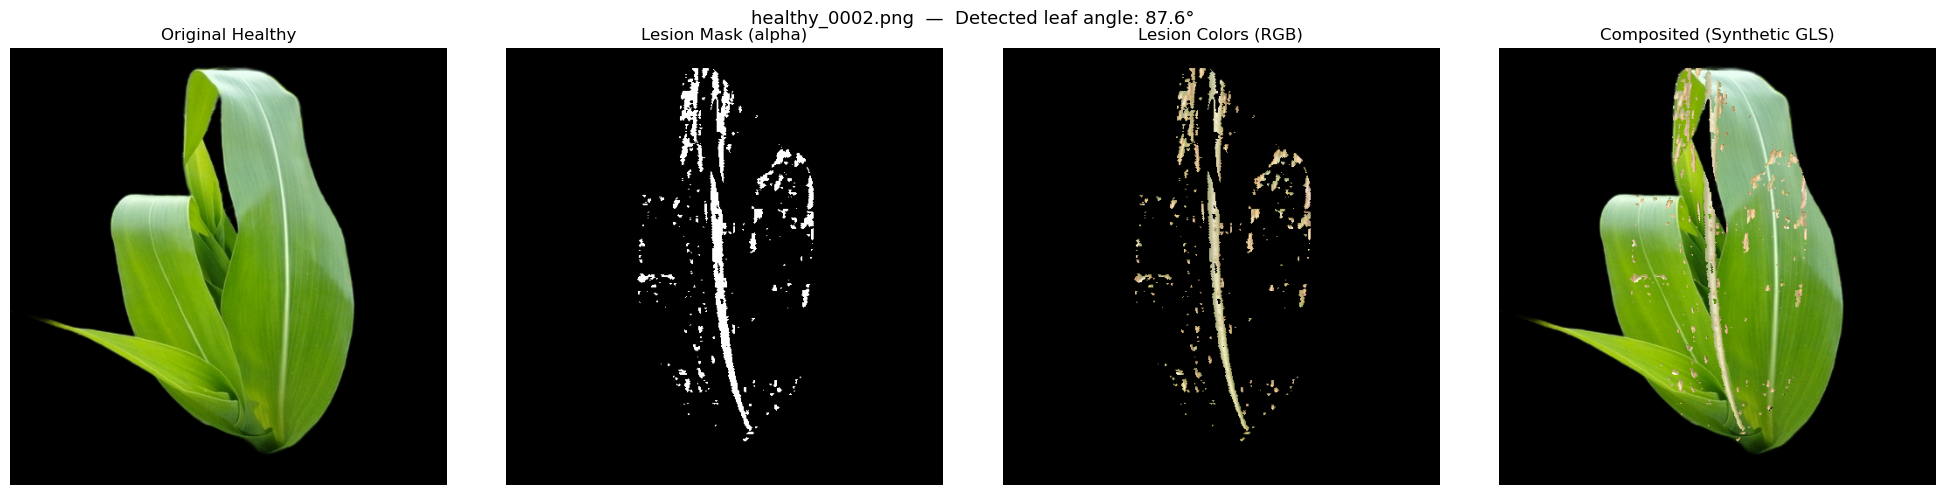

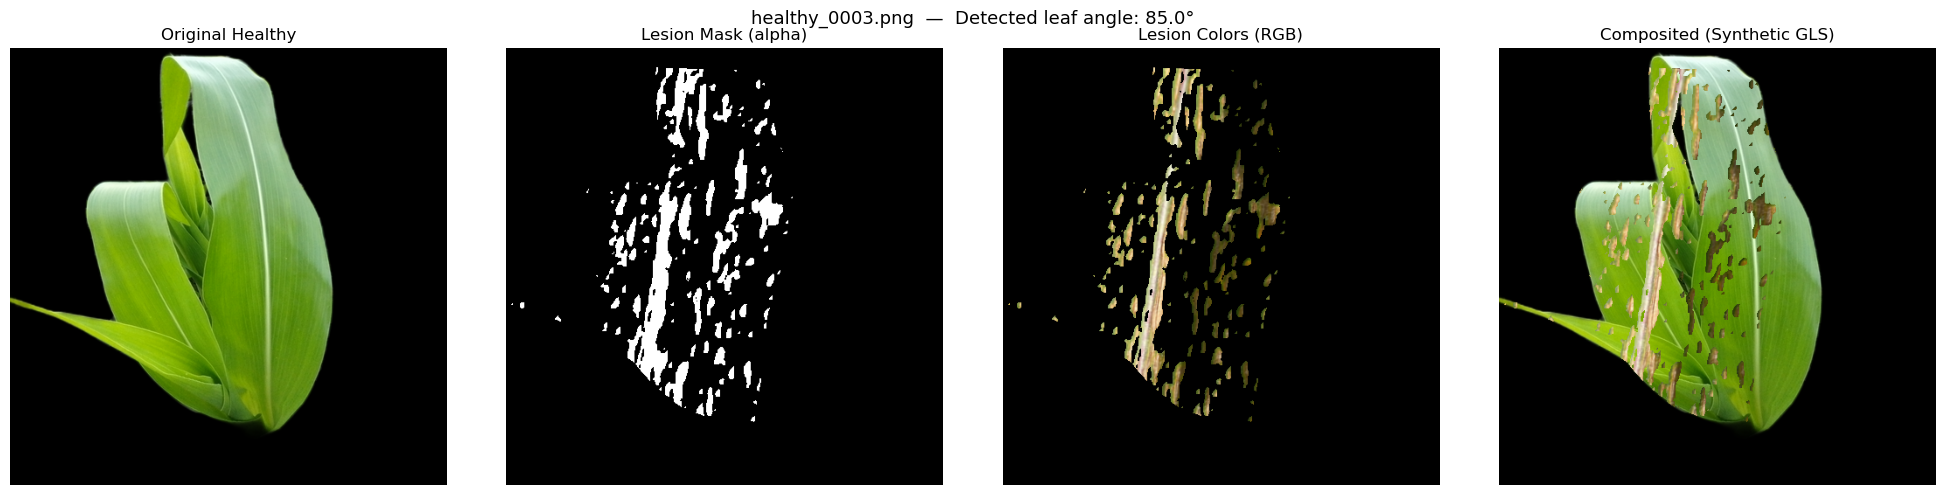

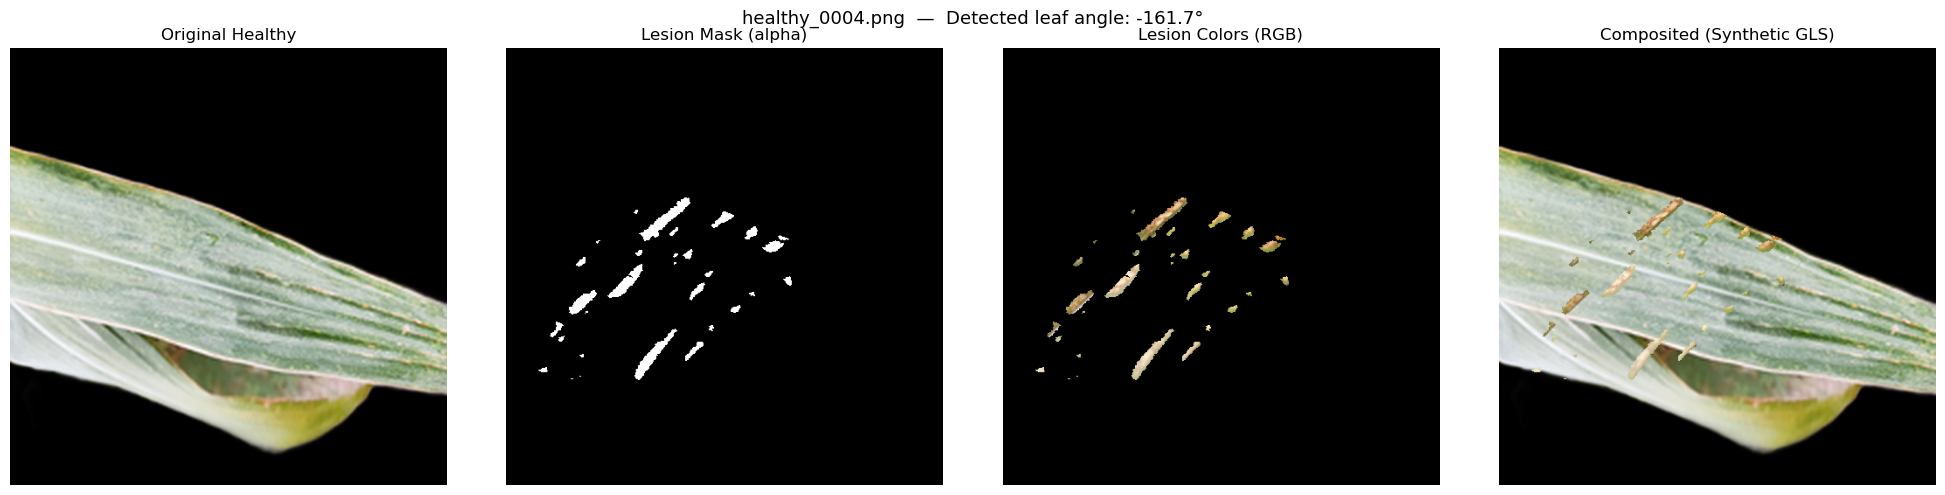

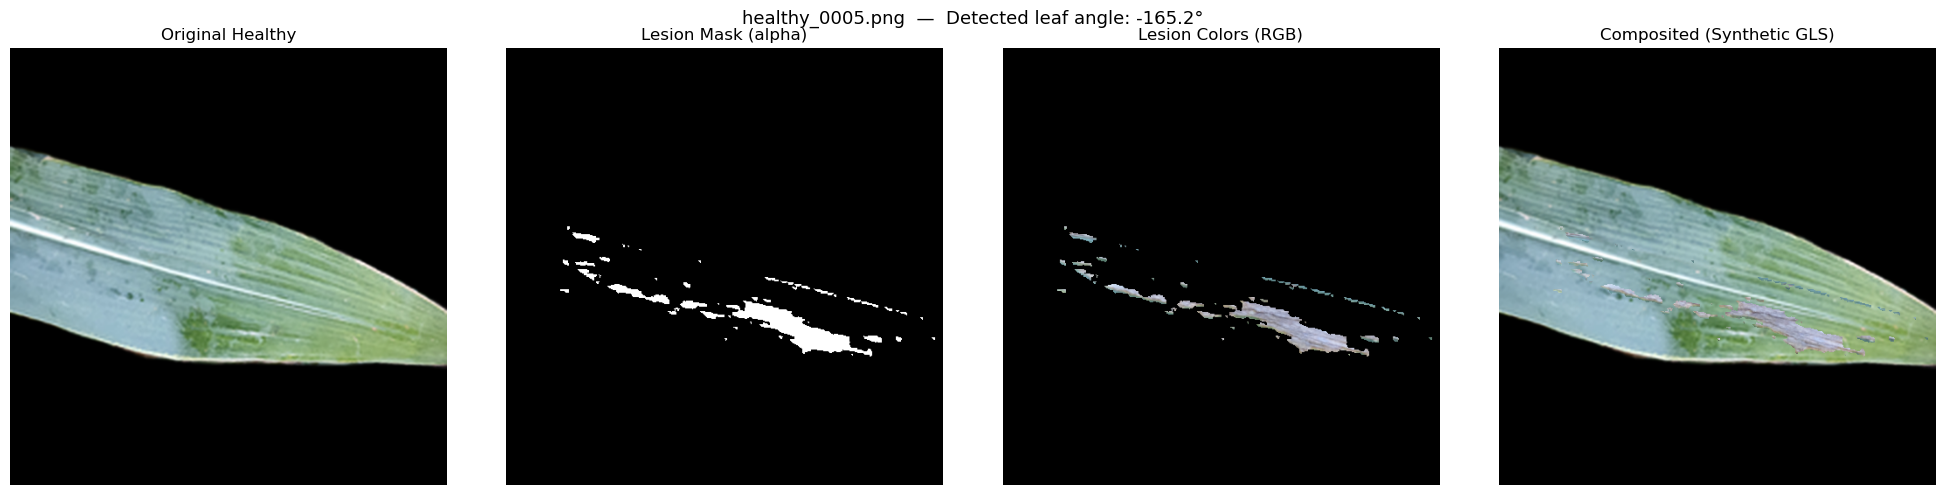

In [4]:
import sys, os
sys.path.insert(0, os.path.abspath('../..'))

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import cv2
from src.data.synthetic_mask_generator import estimate_leaf_angle, gls_synthetic_mask

# --- Reference: show real GLS image (leaf201) ---
gls_img = np.array(Image.open('../../data/diseased/gls/leaf201.png').convert('RGB'))
plt.figure(figsize=(5, 5))
plt.imshow(gls_img)
plt.title('Reference: Real GLS (leaf201.png)')
plt.axis('off')
plt.show()

# --- Load healthy images for comparison ---
healthy_dir = '../../data/healthy'
image_files = [f for f in os.listdir(healthy_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
num_samples = min(5, len(image_files))

for i in range(num_samples):
    img_path = os.path.join(healthy_dir, image_files[i])
    img = np.array(Image.open(img_path).convert('RGB'))
    h, w = img.shape[:2]

    # Create a simple leaf mask by thresholding (leaf vs black background)
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    _, leaf_mask = cv2.threshold(gray, 30, 255, cv2.THRESH_BINARY)

    # Detect leaf orientation
    angle = estimate_leaf_angle(leaf_mask)
    angle_deg = np.degrees(angle)

    # Generate GLS-realistic RGBA mask using real lesion overlays
    # Returns (H, W, 4) RGBA float32, alpha=1 for lesion pixels
    gls_mask_rgba = gls_synthetic_mask((h, w), leaf_mask=leaf_mask)
    gls_alpha = gls_mask_rgba[..., 3]  # binary alpha channel
    gls_rgb = (gls_mask_rgba[..., :3] * 255).astype(np.uint8)

    # Composite: blend lesion colors onto the healthy image using alpha
    img_float = img.astype(np.float32) / 255.0
    alpha_3ch = gls_alpha[..., None]
    composited = (1 - alpha_3ch) * img_float + alpha_3ch * gls_mask_rgba[..., :3]
    composited = (np.clip(composited, 0, 1) * 255).astype(np.uint8)

    fig, axs = plt.subplots(1, 4, figsize=(20, 5))
    fig.suptitle(f'{image_files[i]}  —  Detected leaf angle: {angle_deg:.1f}°', fontsize=13)

    axs[0].imshow(img)
    axs[0].set_title('Original Healthy')
    axs[1].imshow(gls_alpha, cmap='gray')
    axs[1].set_title('Lesion Mask (alpha)')
    axs[2].imshow(gls_rgb)
    axs[2].set_title('Lesion Colors (RGB)')
    axs[3].imshow(composited)
    axs[3].set_title('Composited (Synthetic GLS)')

    for ax in axs.flat:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

In [6]:
# Save generated GLS synthetic RGBA masks to lesion_synthetic folder
import os
from PIL import Image

output_dir = '../../data/masks/lesion_synthetic'
os.makedirs(output_dir, exist_ok=True)

for i in range(len(image_files)):
    img_path = os.path.join(healthy_dir, image_files[i])
    img = np.array(Image.open(img_path).convert('RGB'))
    h, w = img.shape[:2]

    # Create a simple leaf mask by thresholding (leaf vs black background)
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    _, leaf_mask = cv2.threshold(gray, 30, 255, cv2.THRESH_BINARY)

    # Generate GLS-realistic RGBA mask
    gls_mask_rgba = gls_synthetic_mask((h, w), leaf_mask=leaf_mask)

    # Save as RGBA PNG (lesion pixels have color+alpha=1, background is transparent)
    mask_filename = 'mask_' + os.path.splitext(image_files[i])[0] + '.png'
    mask_path = os.path.join(output_dir, mask_filename)
    rgba_uint8 = (np.clip(gls_mask_rgba, 0, 1) * 255).astype(np.uint8)
    Image.fromarray(rgba_uint8, mode='RGBA').save(mask_path)

print(f"Saved {len(image_files)} synthetic RGBA masks to {output_dir}")

Saved 380 synthetic RGBA masks to ../../data/masks/lesion_synthetic


Saved 380 composited healthy images to ../../data/healthy_masked
Saved 380 viewable binary PNG masks (0/255) to ../../data/masks/lesion_synthetic_binary
Saved 380 strict binary masks (0/1, .npy) to ../../data/masks/lesion_synthetic_binary01_npy
Skipped 0 images due to missing RGBA masks
Samples with empty lesion mask: 1


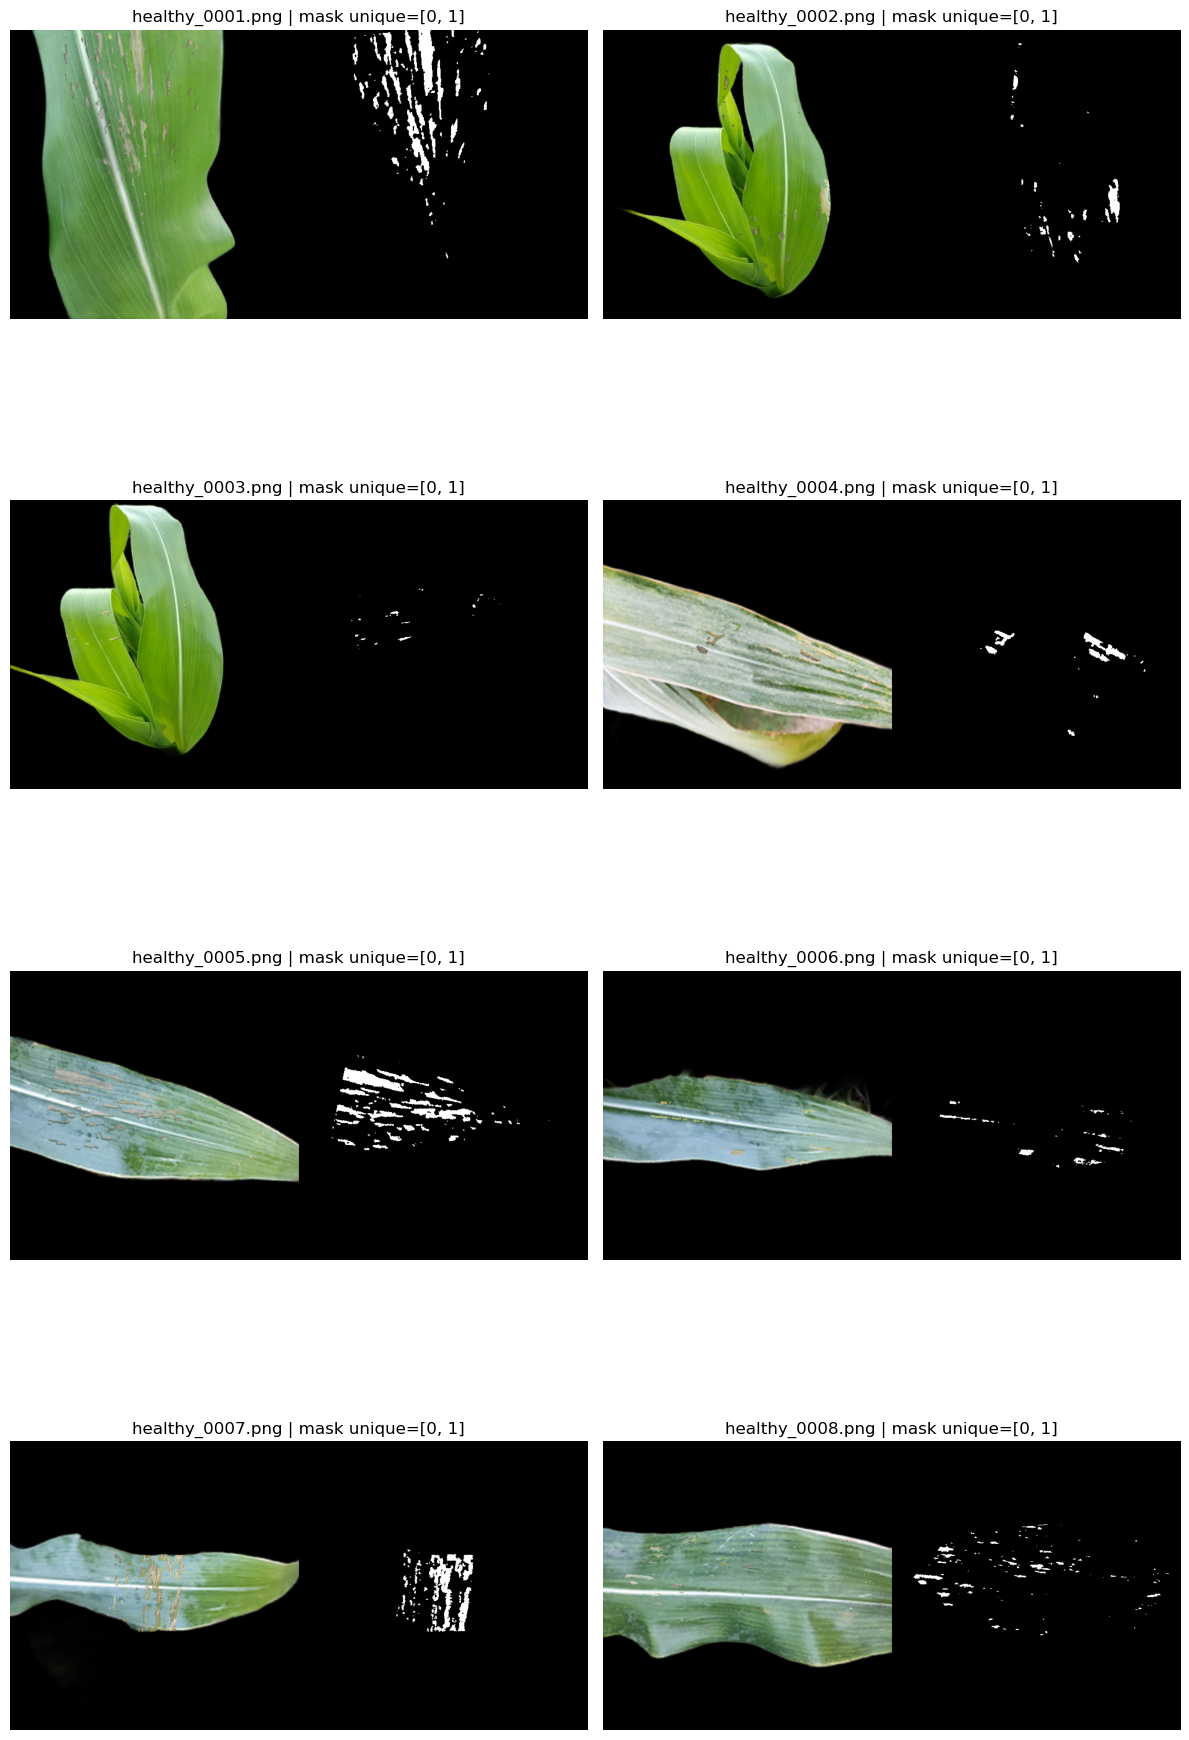

Saved 8 pair preview images + combined preview to ../../results/figures/synthetic_binary_pair_examples


In [10]:
# Apply synthetic RGBA lesion masks to healthy images using Poisson + visibility-preserving blend
import os
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

healthy_dir = '../../data/healthy'
mask_dir = '../../data/masks/lesion_synthetic'
output_dir = '../../data/healthy_masked'
lesion_binary_dir = '../../data/masks/lesion_synthetic_binary'  # viewable PNGs (0/255)
lesion_binary01_dir = '../../data/masks/lesion_synthetic_binary01_npy'  # strict 0/1 arrays (.npy)
preview_dir = '../../results/figures/synthetic_binary_pair_examples'
os.makedirs(output_dir, exist_ok=True)
os.makedirs(lesion_binary_dir, exist_ok=True)
os.makedirs(lesion_binary01_dir, exist_ok=True)
os.makedirs(preview_dir, exist_ok=True)

# Tunable visibility controls
LESION_STRENGTH = 0.65   # higher => lesions more visible (try 0.5 to 0.8)
ALPHA_GAMMA = 0.8        # <1 boosts mid-alpha areas, >1 softens them

image_files = [f for f in os.listdir(healthy_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
image_files.sort()
processed_count = 0
skipped_count = 0
empty_mask_count = 0
saved_names = []

for idx, img_name in enumerate(image_files):
    img_path = os.path.join(healthy_dir, img_name)
    mask_name = 'mask_' + os.path.splitext(img_name)[0] + '.png'
    mask_path = os.path.join(mask_dir, mask_name)

    if not os.path.exists(mask_path):
        print(f"Mask not found for {img_name}, skipping.")
        skipped_count += 1
        continue

    # Destination image (healthy leaf)
    dst_rgb = np.array(Image.open(img_path).convert('RGB'))
    dst_h, dst_w = dst_rgb.shape[:2]

    # Source lesion RGBA (synthetic lesion colors + alpha)
    mask_rgba = np.array(Image.open(mask_path).convert('RGBA'))
    lesion_rgb = mask_rgba[..., :3]
    alpha = mask_rgba[..., 3]

    # True binary mask: 1 where transformed lesion exists, 0 elsewhere
    lesion_mask_binary = np.logical_or(
        np.any(lesion_rgb > 0, axis=2),
        alpha > 0
    ).astype(np.uint8)

    # OpenCV seamlessClone expects 0/255 uint8 mask
    lesion_mask_clone = lesion_mask_binary * 255

    # If no lesion pixels exist, keep original image
    if np.count_nonzero(lesion_mask_binary) == 0:
        composited = dst_rgb
        empty_mask_count += 1
    else:
        ys, xs = np.where(lesion_mask_binary > 0)
        center_x = int(xs.mean())
        center_y = int(ys.mean())

        # Compute lesion bbox so clone ROI stays inside destination image
        x, y, w, h = cv2.boundingRect(np.column_stack((xs, ys)).astype(np.int32))
        half_w = w // 2
        half_h = h // 2
        right_half_w = w - half_w
        bottom_half_h = h - half_h

        # Clamp center to valid range for seamlessClone placement
        min_cx = half_w
        max_cx = max(half_w, dst_w - right_half_w)
        min_cy = half_h
        max_cy = max(half_h, dst_h - bottom_half_h)
        center_x = int(np.clip(center_x, min_cx, max_cx))
        center_y = int(np.clip(center_y, min_cy, max_cy))
        center = (center_x, center_y)

        # Alpha blend (keeps lesion appearance)
        a = (alpha.astype(np.float32) / 255.0)[..., None]
        a = np.clip(a, 0.0, 1.0) ** ALPHA_GAMMA
        alpha_comp = ((1 - a) * dst_rgb.astype(np.float32) + a * lesion_rgb.astype(np.float32))

        try:
            # Poisson blend for composited image only (not for binary mask)
            poisson_comp = cv2.seamlessClone(
                src=lesion_rgb,
                dst=dst_rgb,
                mask=lesion_mask_clone,
                p=center,
                flags=cv2.MIXED_CLONE
            ).astype(np.float32)

            composited_f = (1.0 - LESION_STRENGTH) * poisson_comp + LESION_STRENGTH * alpha_comp
            composited = np.clip(composited_f, 0, 255).astype(np.uint8)
        except cv2.error as e:
            print(f"Poisson failed for {img_name}, using alpha blend. Error: {e}")
            composited = np.clip(alpha_comp, 0, 255).astype(np.uint8)

    # Save paired outputs with the exact same filename stem
    out_name = f"healthy_{idx+1:04d}.png"
    stem = os.path.splitext(out_name)[0]
    out_path = os.path.join(output_dir, out_name)
    binary_vis_path = os.path.join(lesion_binary_dir, out_name)
    binary01_path = os.path.join(lesion_binary01_dir, stem + '.npy')

    Image.fromarray(composited).save(out_path)
    # Viewable PNG mask for folder preview: white lesion (255), black background (0)
    Image.fromarray((lesion_mask_binary * 255).astype(np.uint8), mode='L').save(binary_vis_path)
    # Strict binary file for training/evaluation pipelines: values are exactly 0 or 1
    np.save(binary01_path, lesion_mask_binary)

    processed_count += 1
    saved_names.append(out_name)

print(f"Saved {processed_count} composited healthy images to {output_dir}")
print(f"Saved {processed_count} viewable binary PNG masks (0/255) to {lesion_binary_dir}")
print(f"Saved {processed_count} strict binary masks (0/1, .npy) to {lesion_binary01_dir}")
print(f"Skipped {skipped_count} images due to missing RGBA masks")
print(f"Samples with empty lesion mask: {empty_mask_count}")

# Verification previews: save and display example pairs
num_examples = min(8, len(saved_names))
if num_examples == 0:
    print('No examples available for preview.')
else:
    rows = int(np.ceil(num_examples / 2))
    fig, axs = plt.subplots(rows, 2, figsize=(12, 5 * rows))
    axs = np.array(axs).reshape(-1)

    for i in range(num_examples):
        name = saved_names[i]
        stem = os.path.splitext(name)[0]
        img = np.array(Image.open(os.path.join(output_dir, name)).convert('RGB'))
        mask01 = np.load(os.path.join(lesion_binary01_dir, stem + '.npy'))

        # Render strict 0/1 mask as white/black for human inspection
        vis = np.hstack([img, np.repeat((mask01[..., None] * 255), 3, axis=2)])
        axs[i].imshow(vis)
        axs[i].set_title(f'{name} | mask unique={np.unique(mask01).tolist()}')
        axs[i].axis('off')

        # Save each pair preview too
        Image.fromarray(vis).save(os.path.join(preview_dir, f'pair_{i+1:02d}_{name}'))

    for j in range(num_examples, len(axs)):
        axs[j].axis('off')

    plt.tight_layout()
    combined_preview_path = os.path.join(preview_dir, 'combined_preview.png')
    plt.savefig(combined_preview_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved {num_examples} pair preview images + combined preview to {preview_dir}')

In [11]:
# Save binary masks of the overall leaf (white leaf, black background)
import os
import cv2
import numpy as np
from PIL import Image

healthy_dir = '../../data/gan_a/phase_1/healthy_masked'
mask_dir = '../../data/gan_a/phase_1/healthy_outline'
os.makedirs(mask_dir, exist_ok=True)

image_files = [f for f in os.listdir(healthy_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

for img_name in image_files:
    img_path = os.path.join(healthy_dir, img_name)
    img = np.array(Image.open(img_path).convert('RGB'))
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    _, leaf_mask = cv2.threshold(gray, 30, 255, cv2.THRESH_BINARY)  # white leaf, black background
    mask_path = os.path.join(mask_dir, os.path.splitext(img_name)[0] + '.png')
    Image.fromarray(leaf_mask).save(mask_path)

print(f"Saved {len(image_files)} binary leaf masks to {mask_dir}")

Saved 380 binary leaf masks to ../../data/gan_a/phase_1/healthy_outline
